# NLP Mini Project 1 — Wikipedia Article-Type Classifier (DBpedia-14)

**Course:** Natural Language Processing — Phase 1 (Units 1–4)
**Corpus option:** Option 6 — Wikipedia-based articles (DBpedia-14)
**Task:** Given the text of a Wikipedia article abstract, predict what kind of entity it describes.

### Problem statement (Unit 1)
Wikipedia contains millions of articles, and many applications (search filters, knowledge-base construction,
content recommendation, automatic tagging of new pages) need to know *what type of thing* an article is about.
Doing this by hand does not scale. This project builds a classical NLP pipeline that reads an article abstract
and assigns one of six types: **Company, Artist, Athlete, Building, Film, WrittenWork**.

### Program flow
Corpus → Train/Test separation → Preprocessing → Corpus statistics → N-gram analysis →
Next-word prediction → Bag of Words → Classical classifier → Test metrics → Demo prediction

## 0. Setup

In [1]:
# In Google Colab, first run:  !pip install datasets nltk scikit-learn pandas matplotlib seaborn joblib
import os, sys, json, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

PROJECT_DIR = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(PROJECT_DIR, 'src'))
from preprocessing import preprocess, clean_text, sentences_for_lm, STOP_WORDS
from ngram_lm import NGramLM

DATA_DIR    = os.path.join(PROJECT_DIR, 'data')
MODEL_DIR   = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
FIG_DIR     = os.path.join(RESULTS_DIR, 'figures')
for d in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid')
print('Project dir:', PROJECT_DIR)

Project dir: C:\Users\MSS\AppData\Local\Project-Data\claude_pzs8sxrjxfjjc\scratch-workspaces\975872f5-76f3-49c9-9a2b-fe6b754404c5\2975f408-ec8d-4f77-84d2-901c350b2a66\scratch-2026-11-05-1fc678\NLP_Project1_DBpedia


## 1. Corpus acquisition and understanding

**DBpedia-14** (Zhang, Zhao & LeCun, 2015) contains Wikipedia abstracts extracted through DBpedia, labelled with
14 non-overlapping ontology classes. Each record has `title`, `content` (the abstract) and `label`.
The official split has 560,000 training and 70,000 test examples (40,000 / 5,000 per class).

**Design choices (documented as required):**
- **Classes:** 6 of the 14 — Company, Artist, Athlete, Building, Film, WrittenWork. They cover organisations,
  people, places and creative works, and include pairs that are expected to be confusable (Film vs WrittenWork,
  Artist vs Film/WrittenWork, Company vs Building).
- **Text field:** *content only*. The title is just a name (e.g. "E. D. Abbott Ltd") and usually reappears at the
  start of the content, so it adds little; using the content alone makes the task depend on language, not names.
- **Training data:** a balanced, reproducible subset of **3,000 articles per class (18,000)** sampled from the
  official training split with `random_state=42`.
- **Test data:** **all** official test examples of the 6 classes (**30,000**, 5,000 per class). They are never used
  for building the vocabulary, model selection or tuning — only for the final evaluation.

In [2]:
SELECTED_CLASSES = ['Company', 'Artist', 'Athlete', 'Building', 'Film', 'WrittenWork']
TRAIN_PER_CLASS = 3000
TRAIN_CSV = os.path.join(DATA_DIR, 'train.csv')
TEST_CSV  = os.path.join(DATA_DIR, 'test.csv')

if os.path.exists(TRAIN_CSV) and os.path.exists(TEST_CSV):
    # Frozen split already saved: always reuse it so results are reproducible.
    train_df = pd.read_csv(TRAIN_CSV)
    test_df  = pd.read_csv(TEST_CSV)
    print('Loaded frozen split from data/')
else:
    from datasets import load_dataset
    ds = load_dataset('fancyzhx/dbpedia_14')
    names = ds['train'].features['label'].names

    def to_frame(split):
        df = ds[split].to_pandas().reset_index().rename(columns={'index': 'orig_idx'})
        df['label_name'] = df['label'].map(lambda i: names[i])
        df['text'] = df['content'].str.strip()
        return df[df['label_name'].isin(SELECTED_CLASSES)][['orig_idx', 'title', 'text', 'label_name']]

    train_full, test_full = to_frame('train'), to_frame('test')
    train_df = (train_full.groupby('label_name').sample(n=TRAIN_PER_CLASS, random_state=SEED)
                .sample(frac=1, random_state=SEED).reset_index(drop=True))
    test_df = test_full.reset_index(drop=True)          # official test split, untouched
    train_df.to_csv(TRAIN_CSV, index=False)
    test_df.to_csv(TEST_CSV, index=False)
    print('Created and saved the frozen split to data/train.csv and data/test.csv')

print('Train:', train_df.shape, ' Test:', test_df.shape)
train_df.head()

Loaded frozen split from data/
Train: (18000, 4)  Test: (30000, 4)


,orig_idx,title,text,label_name
0,93172,Takayuki Yamada,Takayuki Yamada (山田 孝之 Yamada Takayuki born October 20 1983 in Satsumasendai Kagoshima) is a Japanese actor and singer.,Artist
1,257909,John Brown IV House,John Brown IV is a historic colonial house at 703 Pearse Road in Swansea Massachusetts.The house was built in 1752 a...,Building
2,31721,Bevin Brothers Manufacturing Company,Bevin Brothers Manufacturing company (also called Bevin Brothers) is a family-owned bell foundry located in East Ham...,Company
3,144071,Miguel María Lasa,Miguel María Lasa Urquía (born November 4 1947 in Oiartzun) is a Spanish former road bicycle racer. He won four stag...,Athlete
4,94563,Rudi Stephan,Rudi Stephan (29 July 1887 Worms Grand Duchy of Hesse – 29 September 1915) was a German composer of great promise wh...,Artist


In [3]:
# Sanity check: no article text appears in both train and test
overlap = set(train_df.text) & set(test_df.text)
print('Texts shared between train and test:', len(overlap))
print('\nOne example per class (train):')
for c in SELECTED_CLASSES:
    row = train_df[train_df.label_name == c].iloc[0]
    print(f'\n[{c}] {row.title}\n  {row.text[:220]}...')

Texts shared between train and test: 0

One example per class (train):



[Company] Bevin Brothers Manufacturing Company
  Bevin Brothers Manufacturing company (also called Bevin Brothers) is a family-owned bell foundry located in East Hampton Connecticut....

[Artist] Takayuki Yamada
  Takayuki Yamada (山田 孝之 Yamada Takayuki born October 20 1983 in Satsumasendai Kagoshima) is a Japanese actor and singer....

[Athlete] Miguel María Lasa
  Miguel María Lasa Urquía (born November 4 1947 in Oiartzun) is a Spanish former road bicycle racer. He won four stages in the Vuelta a España as well as the Points classification in 1975 Vuelta a España. He also finished...

[Building] John Brown IV House
  John Brown IV is a historic colonial house at 703 Pearse Road in Swansea Massachusetts.The house was built in 1752 and added to the National Historic Register in 1990....

[Film] Gibraltar (1938 film)
  Gibraltar is a 1938 French drama film directed by Fedor Ozep and starring Viviane Romance Roger Duchesne Abel Jacquin and Erich von Stroheim....

[WrittenWork] Damned Goo

## 2. Text preprocessing (Unit 2)

One reusable function, `preprocess()` in `src/preprocessing.py`, is used for statistics, N-grams, the classifier
and the demo:

1. **Normalization** — lowercase, remove URLs, digits and punctuation, collapse whitespace.
2. **Tokenization** — NLTK `word_tokenize`.
3. **Stop-word removal** — NLTK English stop-word list (179 words).
4. **Lemmatization** — WordNet lemmatizer (chosen over stemming because it keeps real words, which makes the
   N-gram tables and classifier features readable; a stemming comparison is shown below).
5. Tokens shorter than 2 characters are dropped.

For the **language model** a lighter version (`sentences_for_lm`) keeps stop words and word forms, because
function words ("was", "the", "by") are exactly what a next-word predictor must learn.

In [4]:
examples = train_df.groupby('label_name').head(1).text.tolist()[:3]
for t in examples:
    print('ORIGINAL :', t[:200])
    print('CLEANED  :', clean_text(t)[:200])
    print('LEMMA    :', preprocess(t)[:25])
    print('STEM     :', preprocess(t, normalize='stem')[:25])
    print('-' * 100)

ORIGINAL : Takayuki Yamada (山田 孝之 Yamada Takayuki born October 20 1983 in Satsumasendai Kagoshima) is a Japanese actor and singer.
CLEANED  : takayuki yamada yamada takayuki born october in satsumasendai kagoshima is a japanese actor and singer


LEMMA    : ['takayuki', 'yamada', 'yamada', 'takayuki', 'born', 'october', 'satsumasendai', 'kagoshima', 'japanese', 'actor', 'singer']
STEM     : ['takayuki', 'yamada', 'yamada', 'takayuki', 'born', 'octob', 'satsumasendai', 'kagoshima', 'japanes', 'actor', 'singer']
----------------------------------------------------------------------------------------------------
ORIGINAL : John Brown IV is a historic colonial house at 703 Pearse Road in Swansea Massachusetts.The house was built in 1752 and added to the National Historic Register in 1990.
CLEANED  : john brown iv is a historic colonial house at pearse road in swansea massachusetts the house was built in and added to the national historic register in
LEMMA    : ['john', 'brown', 'iv', 'historic', 'colonial', 'house', 'pearse', 'road', 'swansea', 'massachusetts', 'house', 'built', 'added', 'national', 'historic', 'register']
STEM     : ['john', 'brown', 'iv', 'histor', 'coloni', 'hous', 'pears', 'road', 'swansea', 'massachusett', 'ho

In [5]:
t0 = time.time()
train_df['tokens'] = train_df.text.apply(preprocess)
test_df['tokens']  = test_df.text.apply(preprocess)
train_df['clean']  = train_df.tokens.str.join(' ')
test_df['clean']   = test_df.tokens.str.join(' ')
print(f'Preprocessed {len(train_df) + len(test_df):,} documents in {time.time() - t0:.1f}s')
train_df[['label_name', 'text', 'clean']].head(5)

Preprocessed 48,000 documents in 35.4s


,label_name,text,clean
0,Artist,Takayuki Yamada (山田 孝之 Yamada Takayuki born October 20 1983 in Satsumasendai Kagoshima) is a Japanese actor and singer.,takayuki yamada yamada takayuki born october satsumasendai kagoshima japanese actor singer
1,Building,John Brown IV is a historic colonial house at 703 Pearse Road in Swansea Massachusetts.The house was built in 1752 a...,john brown iv historic colonial house pearse road swansea massachusetts house built added national historic register
2,Company,Bevin Brothers Manufacturing company (also called Bevin Brothers) is a family-owned bell foundry located in East Ham...,bevin brother manufacturing company also called bevin brother family owned bell foundry located east hampton connect...
3,Athlete,Miguel María Lasa Urquía (born November 4 1947 in Oiartzun) is a Spanish former road bicycle racer. He won four stag...,miguel maria lasa urquia born november oiartzun spanish former road bicycle racer four stage vuelta espana well poin...
4,Artist,Rudi Stephan (29 July 1887 Worms Grand Duchy of Hesse – 29 September 1915) was a German composer of great promise wh...,rudi stephan july worm grand duchy hesse september german composer great promise shortly first world war considered ...


## 3. Corpus statistics (training split)

In [6]:
raw_tokens = train_df.text.apply(lambda t: clean_text(t).split())
stats = {
    'documents (train)': len(train_df),
    'documents (test)': len(test_df),
    'classes': len(SELECTED_CLASSES),
    'total raw tokens (train)': int(raw_tokens.str.len().sum()),
    'vocabulary size, raw lowercase (train)': len(set(w for ts in raw_tokens for w in ts)),
    'total tokens after preprocessing (train)': int(train_df.tokens.str.len().sum()),
    'vocabulary size after preprocessing (train)': len(set(w for ts in train_df.tokens for w in ts)),
    'avg raw tokens per document': round(raw_tokens.str.len().mean(), 1),
    'avg tokens per document after preprocessing': round(train_df.tokens.str.len().mean(), 1),
}
pd.Series(stats, name='value').to_csv(os.path.join(RESULTS_DIR, 'corpus_statistics.csv'), header=['value'], index_label='statistic')
pd.Series(stats, name='value').to_frame()

,value
documents (train),18000.0
documents (test),30000.0
classes,6.0
total raw tokens (train),856936.0
"vocabulary size, raw lowercase (train)",60711.0
total tokens after preprocessing (train),529455.0
vocabulary size after preprocessing (train),56723.0
avg raw tokens per document,47.6
avg tokens per document after preprocessing,29.4


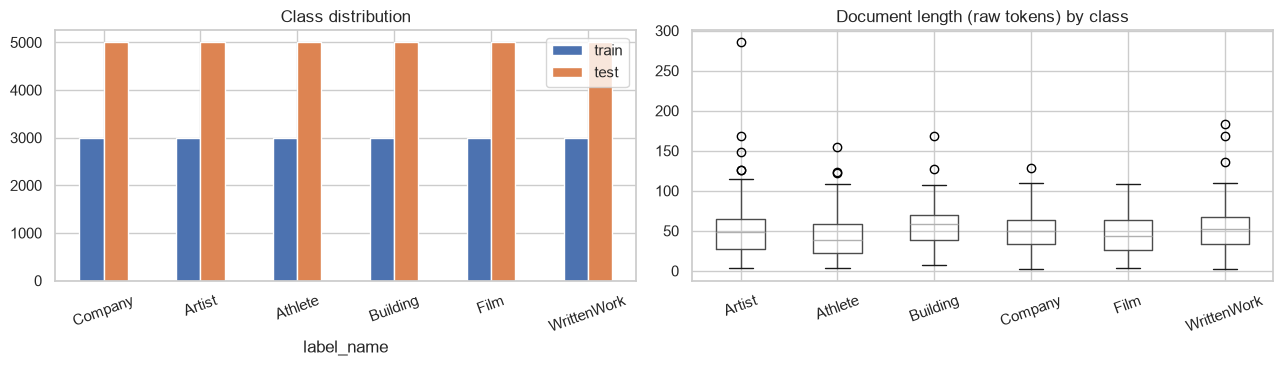

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Artist,3000.0,46.6,22.7,3.0,27.0,48.0,65.0,286.0
Athlete,3000.0,41.1,20.9,4.0,22.0,38.0,58.0,155.0
Building,3000.0,54.2,19.3,7.0,38.0,58.0,70.0,169.0
Company,3000.0,48.4,19.1,2.0,33.0,50.0,64.0,128.0
Film,3000.0,44.9,21.8,4.0,26.0,44.0,64.0,109.0
WrittenWork,3000.0,50.5,20.5,2.0,34.0,52.0,67.0,183.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.DataFrame({'train': train_df.label_name.value_counts(), 'test': test_df.label_name.value_counts()}) \
  .loc[SELECTED_CLASSES].plot.bar(ax=axes[0], rot=20, title='Class distribution')
train_df.assign(n=raw_tokens.str.len()).boxplot(column='n', by='label_name', ax=axes[1], rot=20)
axes[1].set_title('Document length (raw tokens) by class'); axes[1].set_xlabel(''); plt.suptitle('')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'class_distribution_length.png'), dpi=120); plt.show()
train_df.assign(n=raw_tokens.str.len()).groupby('label_name').n.describe().round(1)

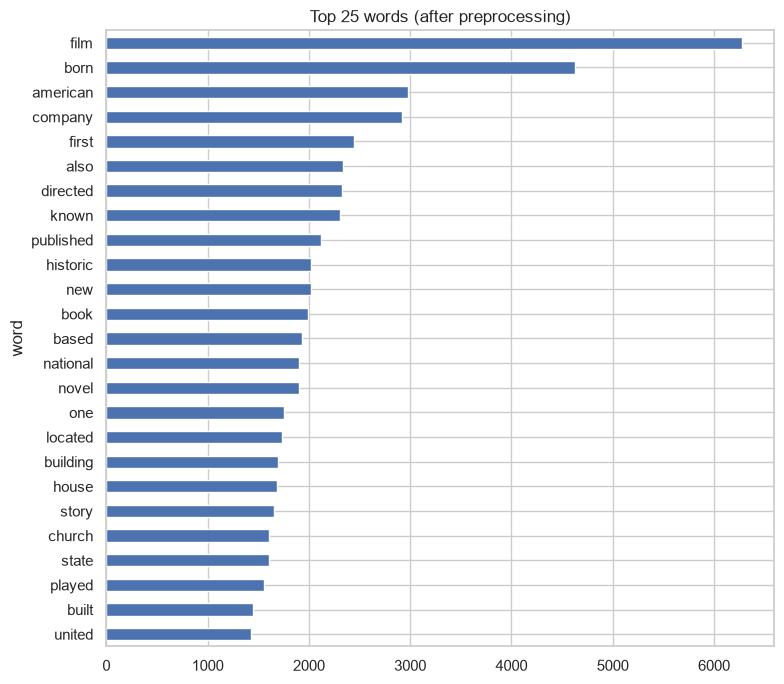

Words that occur only once (hapax legomena): 30,269 (53.4% of the vocabulary)


In [8]:
word_freq = Counter(w for ts in train_df.tokens for w in ts)
top = pd.DataFrame(word_freq.most_common(25), columns=['word', 'count'])
top.plot.barh(x='word', y='count', figsize=(8, 7), legend=False, title='Top 25 words (after preprocessing)').invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'top_words.png'), dpi=120); plt.show()

hapax = sum(1 for c in word_freq.values() if c == 1)
print(f'Words that occur only once (hapax legomena): {hapax:,} ({hapax / len(word_freq):.1%} of the vocabulary)')

**Observations**
- The classes are perfectly balanced (3,000 train / 5,000 test each), so accuracy is a meaningful metric and macro
  averages equal weighted averages.
- Documents are short abstracts (around 45–50 raw tokens on average), with few very long outliers.
- Preprocessing roughly halves the number of tokens (stop words removed) and reduces the vocabulary through
  lowercasing and lemmatization.
- The most frequent words are already strongly topical (*film, born, company, directed, published, historic, book, novel*),
  which suggests a Bag-of-Words model will work well. Roughly half of the vocabulary appears only once
  (Zipf's law) — mostly proper nouns — so rare words are filtered with `min_df=2` in the classifier.

## 4. N-gram analysis (Unit 3)

In [9]:
from nltk.util import ngrams

def top_ngrams(token_lists, n, k=15):
    c = Counter()
    for ts in token_lists:
        c.update(ngrams(ts, n))
    return [(' '.join(g), cnt) for g, cnt in c.most_common(k)]

overall = {f'{n}-gram': top_ngrams(train_df.tokens, n) for n in (1, 2, 3)}
pd.DataFrame([{'n': k, 'ngram': g, 'count': c} for k, v in overall.items() for g, c in v]) \
  .to_csv(os.path.join(RESULTS_DIR, 'top_ngrams.csv'), index=False)
pd.DataFrame({k: [f'{g} ({c})' for g, c in v] for k, v in overall.items()})

,1-gram,2-gram,3-gram
0,film (6278),film directed (1454),register historic place (739)
1,born (4624),united state (1020),national register historic (738)
2,american (2981),new york (951),listed national register (439)
3,company (2917),national register (808),added national register (321)
4,first (2448),historic place (746),drama film directed (318)
5,also (2340),register historic (743),new york city (225)
6,directed (2323),also known (666),comedy film directed (190)
7,known (2305),drama film (496),major league baseball (186)
8,published (2122),best known (449),film written directed (169)
9,historic (2017),listed national (440),built added national (147)


In [10]:
def per_class_table(n, k=10):
    return pd.DataFrame({c: [f'{g} ({cnt})' for g, cnt in top_ngrams(train_df[train_df.label_name == c].tokens, n, k)]
                         for c in SELECTED_CLASSES})
for n, name in [(1, 'unigrams'), (2, 'bigrams'), (3, 'trigrams')]:
    pd.DataFrame([{'class': c, 'rank': r + 1, 'ngram': g, 'count': cnt}
                  for c in SELECTED_CLASSES
                  for r, (g, cnt) in enumerate(top_ngrams(train_df[train_df.label_name == c].tokens, n, 15))]) \
      .to_csv(os.path.join(RESULTS_DIR, f'class_{name}.csv'), index=False)
print('Top bigrams per class'); display(per_class_table(2))
print('Top trigrams per class'); display(per_class_table(3))

Top bigrams per class


,Company,Artist,Athlete,Building,Film,WrittenWork
0,record label (239),best known (344),football league (300),national register (807),film directed (1452),first published (390)
1,united state (232),singer songwriter (247),footballer play (269),historic place (745),drama film (496),science fiction (256)
2,company founded (201),new york (194),currently play (245),register historic (742),comedy film (351),peer reviewed (211)
3,company based (170),better known (120),major league (244),listed national (439),film festival (284),short story (161)
4,new york (144),also known (115),football player (242),united state (428),film written (226),novel written (141)
5,united kingdom (89),stage name (114),summer olympics (240),added national (341),written directed (224),united state (136)
6,company headquartered (87),born june (113),footballer played (209),new york (330),film starring (221),newspaper published (134)
7,stock exchange (84),born march (101),born september (205),also known (314),film released (191),fiction novel (117)
8,independent record (83),born august (98),born april (203),th century (258),film star (168),journal published (116)
9,production company (82),born october (96),born february (200),historic district (214),film based (160),book written (116)


Top trigrams per class


,Company,Artist,Athlete,Building,Film,WrittenWork
0,independent record label (81),known stage name (81),major league baseball (185),register historic place (738),drama film directed (318),science fiction novel (102)
1,record label founded (60),new york city (63),professional ice hockey (111),national register historic (737),comedy film directed (190),peer reviewed academic (83)
2,new york city (55),american singer songwriter (56),national football league (110),listed national register (438),film written directed (169),reviewed academic journal (83)
3,wholly owned subsidiary (42),better known stage (55),footballer currently play (104),added national register (321),international film festival (113),peer reviewed scientific (62)
4,record label based (34),best known work (45),played college football (99),built added national (147),cannes film festival (72),reviewed scientific journal (62)
5,video game developer (31),american comic book (25),australian rule footballer (73),county new york (130),comedy drama film (59),daily newspaper published (45)
6,record record label (26),comic book artist (25),football player currently (72),historic home located (115),drama film written (55),manga series written (42)
7,london stock exchange (26),born august american (25),ice hockey player (69),house historic home (86),thriller film directed (51),non fiction book (41)
8,record independent record (25),musician singer songwriter (24),player currently play (63),house historic house (73),documentary film directed (46),series written illustrated (36)
9,united state company (23),born june american (23),professional basketball player (62),grade ii listed (66),romantic comedy film (45),academic journal published (36)


In [11]:
# Distinctive bigrams: frequent in one class but rare in the others (ratio with add-1 smoothing)
bigram_counts = {c: Counter(g for ts in train_df[train_df.label_name == c].tokens for g in ngrams(ts, 2))
                 for c in SELECTED_CLASSES}
distinct, distinct_rows = {}, []
for c in SELECTED_CLASSES:
    others = Counter()
    for o in SELECTED_CLASSES:
        if o != c: others.update(bigram_counts[o])
    scored = [(g, cnt, cnt / (others[g] + 1)) for g, cnt in bigram_counts[c].items() if cnt >= 20]
    scored.sort(key=lambda x: -x[2])
    distinct[c] = [f"{' '.join(g)} ({cnt})" for g, cnt, _ in scored[:10]]
    for g, cnt, ratio in scored[:15]:
        distinct_rows.append({'class': c, 'bigram': ' '.join(g), 'count_in_class': cnt,
                              'count_in_other_classes': others[g], 'ratio': round(ratio, 2)})
pd.DataFrame(distinct_rows).to_csv(os.path.join(RESULTS_DIR, 'characteristic_bigrams.csv'), index=False)
pd.DataFrame(distinct)

,Company,Artist,Athlete,Building,Film,WrittenWork
0,company headquartered (87),italian painter (50),footballer play (269),national register (807),drama film (496),newspaper published (134)
1,airline based (78),american singer (79),footballer played (209),historic place (745),film directed (1452),journal published (116)
2,label founded (62),american artist (38),currently playing (167),register historic (742),film written (226),scientific journal (84)
3,wholly owned (53),singer songwriter (247),footballer currently (159),added national (341),comedy film (351),first published (390)
4,commercial bank (46),musician singer (33),professional footballer (156),listed national (439),thriller film (94),reviewed scientific (62)
5,owned subsidiary (45),american jazz (29),football league (300),house historic (203),written directed (224),book written (116)
6,company based (170),stage name (114),major league (244),historic home (154),cannes film (74),novel american (56)
7,main base (42),pornographic actress (27),summer olympics (240),built added (149),language film (73),journal covering (50)
8,holding company (42),known stage (81),played college (114),building located (149),film released (191),series written (88)
9,game developer (41),multi instrumentalist (27),professional ice (111),parish church (134),film star (168),peer reviewed (211)


In [12]:
# Bigrams shared by several classes — sources of possible confusion
shared = []
for g in set().union(*[set(dict(bigram_counts[c].most_common(300))) for c in SELECTED_CLASSES]):
    present = [c for c in SELECTED_CLASSES if bigram_counts[c][g] >= 15]
    if len(present) >= 2:
        shared.append((' '.join(g), ', '.join(f'{c}:{bigram_counts[c][g]}' for c in present)))
pd.DataFrame(sorted(shared, key=lambda x: -sum(int(p.split(':')[1]) for p in x[1].split(', ')))[:15],
             columns=['bigram', 'counts per class'])

,bigram,counts per class
0,united state,"Company:232, Artist:95, Athlete:49, Building:428, Film:80, WrittenWork:136"
1,new york,"Company:144, Artist:194, Athlete:109, Building:330, Film:59, WrittenWork:115"
2,also known,"Company:58, Artist:115, Building:314, Film:131, WrittenWork:36"
3,best known,"Company:45, Artist:344, Athlete:26, WrittenWork:18"
4,th century,"Company:25, Artist:49, Building:258, Film:27, WrittenWork:46"
5,science fiction,"Artist:44, Film:63, WrittenWork:256"
6,born march,"Artist:101, Athlete:195"
7,born may,"Artist:90, Athlete:195"
8,born june,"Artist:113, Athlete:172"
9,born april,"Artist:77, Athlete:203"


**What the N-grams reveal**
- **Unigrams** show the topic vocabulary of each type (film, company, album, player, building, novel).
- **Bigrams/trigrams** capture fixed Wikipedia phrasing that is highly class-specific: *football player*,
  *professional ice hockey*, *directed by*, *national register historic place*, *record label*, *new york times
  best seller*, *founded in*, *headquartered in*. These multi-word cues are more precise than single words.
- **Distinctive bigrams** (frequent in one class, rare elsewhere) are almost perfect indicators of their class,
  explaining why a simple bag-of-words classifier is very accurate on this corpus.
- **Shared bigrams** such as *united state(s)*, *new york*, *also known* or *th century* (from "19th century"
  after digits are removed) occur in almost every class; they describe places and dates, not the entity type, and
  carry little class information. *born + month* is shared by the two "person" classes (Artist and Athlete), so
  the classifier must rely on other words (*painter*, *singer* vs *footballer*, *league*) to separate them.
- Lemmatization merges *united states* into *united state*, a small side effect of word-level normalization.

## 5. N-gram language model and next-word prediction (Unit 3)

A **bigram** and a **trigram** model are trained on sentences of the *training* articles only (stop words kept).
Sentences get `<s>` / `</s>` markers. Unseen N-grams must not get zero probability, so two smoothing methods
are compared using **perplexity on unseen test sentences** (2,000 test articles):

- **Add-k smoothing** (k = 0.01): add a small count to every possible N-gram.
- **Linear interpolation**: mix the trigram, bigram and unigram estimates,
  $P(w \mid a,b) = \lambda_3 P_{ML}(w \mid a,b) + \lambda_2 P_{ML}(w \mid b) + \lambda_1 P_{add1}(w)$
  (bigram model: $\lambda_2 P_{ML}(w \mid b) + \lambda_1 P_{add1}(w)$). The weights $\lambda$ are chosen on a
  **validation set taken from the training articles (10%)** — never on the test set.

For next-word prediction the model uses the trigram context when it has been seen and **backs off** to the bigram
(then unigram) otherwise. Words never seen in training are skipped when computing perplexity.

In [13]:
lm_train_sents = [s for t in train_df.text for s in sentences_for_lm(t)]
lm_test_sents  = [s for t in test_df.sample(2000, random_state=SEED).text for s in sentences_for_lm(t)]
print(f'LM training sentences: {len(lm_train_sents):,}   held-out test sentences: {len(lm_test_sents):,}')

# 1) Choose interpolation weights on a validation slice of the TRAINING articles
val_idx = train_df.sample(frac=0.1, random_state=SEED).index
fit_sents = [s for t in train_df.drop(val_idx).text for s in sentences_for_lm(t)]
val_sents = [s for t in train_df.loc[val_idx].text for s in sentences_for_lm(t)]
grids = {2: [(0.8, 0.2), (0.7, 0.3), (0.6, 0.4), (0.5, 0.5)],
         3: [(0.6, 0.3, 0.1), (0.4, 0.4, 0.2), (0.3, 0.5, 0.2), (0.2, 0.5, 0.3), (0.1, 0.6, 0.3)]}
best_lambdas, tuning_rows = {}, []
for n, grid in grids.items():
    lm = NGramLM(n=n).fit(fit_sents)
    for lam in grid:
        lm.lambdas = lam
        tuning_rows.append({'model': f'{n}-gram', 'lambdas': lam, 'validation perplexity': round(lm.perplexity(val_sents), 1)})
    best = min((r for r in tuning_rows if r['model'] == f'{n}-gram'), key=lambda r: r['validation perplexity'])
    best_lambdas[n] = best['lambdas']
pd.DataFrame(tuning_rows).to_csv(os.path.join(RESULTS_DIR, 'lm_lambda_tuning.csv'), index=False)
display(pd.DataFrame(tuning_rows))
print('Selected lambdas:', best_lambdas)

# 2) Fit the final models on all training sentences and evaluate once on unseen test sentences
lms = {(n, sm): NGramLM(n=n, smoothing=sm, lambdas=best_lambdas[n]).fit(lm_train_sents)
       for n in (2, 3) for sm in ('addk', 'interp')}
bigram_lm, trigram_lm = lms[(2, 'interp')], lms[(3, 'interp')]
print(f'Vocabulary size: {trigram_lm.V:,}')
print(f'P_ML(by | directed)       = {trigram_lm.bigrams[("directed", "by")] / trigram_lm.unigrams["directed"]:.3f}')
print(f'P_ML(player | football)   = {trigram_lm.bigrams[("football", "player")] / trigram_lm.unigrams["football"]:.3f}')
print(f'P_ML(in | was founded)    = {trigram_lm.trigrams[("was", "founded", "in")] / trigram_lm.bigrams[("was", "founded")]:.3f}')

ppl = pd.DataFrame([{'model': f'{"bigram" if n == 2 else "trigram"}', 'smoothing': 'add-k (k=0.01)' if sm == 'addk' else 'interpolation',
                     'test perplexity': round(lm.perplexity(lm_test_sents), 1)} for (n, sm), lm in lms.items()])
ppl.to_csv(os.path.join(RESULTS_DIR, 'lm_perplexity.csv'), index=False)
ppl

LM training sentences: 43,800   held-out test sentences: 4,837


,model,lambdas,validation perplexity
0,2-gram,"(0.8, 0.2)",322.5
1,2-gram,"(0.7, 0.3)",307.0
2,2-gram,"(0.6, 0.4)",304.8
3,2-gram,"(0.5, 0.5)",312.1
4,3-gram,"(0.6, 0.3, 0.1)",361.3
5,3-gram,"(0.4, 0.4, 0.2)",293.3
6,3-gram,"(0.3, 0.5, 0.2)",288.4
7,3-gram,"(0.2, 0.5, 0.3)",274.0
8,3-gram,"(0.1, 0.6, 0.3)",280.8


Selected lambdas: {2: (0.6, 0.4), 3: (0.2, 0.5, 0.3)}


Vocabulary size: 60,681
P_ML(by | directed)       = 0.944
P_ML(player | football)   = 0.196
P_ML(in | was founded)    = 0.700


,model,smoothing,test perplexity
0,bigram,add-k (k=0.01),708.1
1,bigram,interpolation,287.7
2,trigram,add-k (k=0.01),3934.5
3,trigram,interpolation,254.0


In [14]:
prompts = ['the film was directed', 'he is a professional', 'the company was founded',
           'the novel was written', 'the building is located', 'she is an american',
           'the airline is based', 'the church was built in']
rows = []
for p in prompts:
    toks = clean_text(p).split()
    preds, used = trigram_lm.predict_next(toks, top_k=5)
    rows.append({'prompt': p, 'context used': used,
                 'top-5 next words (probability)': ', '.join(f'{w} ({pr:.2f})' for w, pr in preds),
                 'greedy continuation': trigram_lm.generate(toks, max_words=8)})
pd.DataFrame(rows).to_csv(os.path.join(RESULTS_DIR, 'next_word_predictions.csv'), index=False)
pd.DataFrame(rows)

,prompt,context used,top-5 next words (probability),greedy continuation
0,the film was directed,trigram,"by (0.94), and (0.04), written (0.01), officially (0.01), sri (0.01)",the film was directed by john ford
1,he is a professional,trigram,"baseball (0.14), footballer (0.12), american (0.06), football (0.06), rugby (0.04)",he is a professional baseball player
2,the company was founded,trigram,"in (0.70), by (0.19), as (0.04), on (0.02), and (0.01)",the company was founded in by the american writer of the same
3,the novel was written,trigram,"by (0.62), and (0.13), in (0.09), for (0.04), directed (0.02)",the novel was written by the american writer of the same name
4,the building is located,trigram,"in (0.45), at (0.23), on (0.18), along (0.02), near (0.02)",the building is located in the united states
5,she is an american,trigram,"professional (0.06), football (0.05), singer (0.05), musician (0.03), author (0.03)",she is an american professional baseball player
6,the airline is based,trigram,"on (0.72), in (0.22), upon (0.03), at (0.02), out (0.01)",the airline is based on the national register of historic places in
7,the church was built in,trigram,"and (0.33), </s> (0.17), the (0.10), by (0.08), in (0.04)",the church was built in and is a historic home located at the


**Interpretation**
- The model learned typical Wikipedia phrasing: *"the film was directed" → by*, *"he is a professional" →
  football/baseball/ice…*, *"the company was founded" → in*. The predictions also reveal the entity type, which
  links the language model to the classification task.
- **Smoothing matters as much as the order of the model.** With add-k smoothing the trigram is *worse* than the
  bigram: most trigram contexts are rare, so adding k to all ~60,000 possible next words gives far too much
  probability to unseen words. With interpolation the trigram is better than the bigram, because it uses the
  extra context when it exists and falls back on bigram/unigram evidence when it does not.
- The tuned weights give the trigram estimate a *small* share (λ₃ ≈ 0.2): with under a million training tokens
  most trigrams are seen only once or never, so the model learns to trust the bigram more.
- This shows the sparsity trade-off from Unit 3: a larger *n* gives more context but many more unseen N-grams.
- Greedy generation quickly becomes generic or repetitive: N-gram models only see 1–2 previous words.
  Because numbers were removed in preprocessing, phrases such as *"founded in 1990"* become *"founded in"*,
  which also shows up in the continuations. These limitations are addressed by neural and Transformer language
  models in Project 2.

## 6. Bag of Words + classical classifier (Unit 4)

- **Representation:** `CountVectorizer` (Bag of Words), fitted on the **training texts only**. `min_df=2` removes
  words seen in a single document (mostly names), keeping the vocabulary manageable.
- **Classifiers:** Multinomial Naive Bayes and Logistic Regression.
- **Model selection on a validation set:** 10% of the training articles (1,800, stratified, `random_state=42`) are
  held out. Each configuration — classifier × features (single words, or words + word pairs) × settings — is trained
  on the other 90% and scored on the validation set. The best configuration is then retrained on all 18,000
  training articles. The test set is not used for any of these choices.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

X_train, y_train = train_df.clean, train_df.label_name
X_test,  y_test  = test_df.clean,  test_df.label_name
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.10, stratify=y_train, random_state=SEED)
print(f'Fit: {len(X_fit):,}  Validation: {len(X_val):,}  (both from the training set)')

def make_pipeline(model_name, ngram_range, param):
    clf = MultinomialNB(alpha=param) if model_name == 'Naive Bayes' else LogisticRegression(max_iter=3000, C=param)
    return Pipeline([('bow', CountVectorizer(min_df=2, ngram_range=ngram_range)), ('clf', clf)])

grid = ([('Naive Bayes', ng, a) for ng in [(1, 1), (1, 2)] for a in [0.1, 0.5, 1.0]] +
        [('Logistic Regression', ng, C) for ng in [(1, 1), (1, 2)] for C in [0.1, 0.5, 1.0]])
val_rows = []
for model_name, ng, param in grid:
    pipe = make_pipeline(model_name, ng, param).fit(X_fit, y_fit)
    pred = pipe.predict(X_val)
    val_rows.append({'model': model_name, 'features': 'words' if ng == (1, 1) else 'words + word pairs',
                     'setting': f"{'alpha' if model_name == 'Naive Bayes' else 'C'}={param}",
                     'n_features': len(pipe.named_steps['bow'].vocabulary_),
                     'val_accuracy': accuracy_score(y_val, pred), 'val_macro_f1': f1_score(y_val, pred, average='macro'),
                     '_cfg': (model_name, ng, param)})
val_table = pd.DataFrame(val_rows).sort_values('val_accuracy', ascending=False).reset_index(drop=True)
val_table.drop(columns='_cfg').round(4).to_csv(os.path.join(RESULTS_DIR, 'validation_experiments.csv'), index=False)
best_cfg = val_table.iloc[0]['_cfg']
best_name = best_cfg[0]
print('Selected on validation:', best_cfg)
val_table.drop(columns='_cfg').round(4)

Fit: 16,200  Validation: 1,800  (both from the training set)


Selected on validation: ('Logistic Regression', (1, 2), 1.0)


,model,features,setting,n_features,val_accuracy,val_macro_f1
0,Logistic Regression,words + word pairs,C=1.0,57288,0.9672,0.9673
1,Logistic Regression,words + word pairs,C=0.5,57288,0.9656,0.9656
2,Logistic Regression,words + word pairs,C=0.1,57288,0.9650,0.9651
3,Logistic Regression,words,C=0.5,20052,0.9650,0.9651
4,Logistic Regression,words,C=0.1,20052,0.9633,0.9635
5,Naive Bayes,words + word pairs,alpha=1.0,57288,0.9633,0.9633
6,Naive Bayes,words + word pairs,alpha=0.5,57288,0.9633,0.9633
7,Logistic Regression,words,C=1.0,20052,0.9633,0.9634
8,Naive Bayes,words + word pairs,alpha=0.1,57288,0.9583,0.9583
9,Naive Bayes,words,alpha=1.0,20052,0.9528,0.9528


In [16]:
model = make_pipeline(*best_cfg).fit(X_train, y_train)      # retrain on all 18,000 training articles
vectorizer = model.named_steps['bow']
X_bow = vectorizer.transform(X_train)
print(f'BoW matrix (train): {X_bow.shape[0]:,} documents x {X_bow.shape[1]:,} features, '
      f'{X_bow.nnz / np.prod(X_bow.shape):.3%} non-zero (very sparse)')
print('Example vector (first document), non-zero entries:')
row = X_bow[0]
print({vectorizer.get_feature_names_out()[j]: int(v) for j, v in zip(row.indices[:15], row.data[:15])})

joblib.dump(model, os.path.join(MODEL_DIR, 'bow_classifier.joblib'))            # full pipeline (used by demo.py)
joblib.dump(vectorizer, os.path.join(MODEL_DIR, 'bow_vectorizer.joblib'))       # CountVectorizer alone
joblib.dump(model.named_steps['clf'], os.path.join(MODEL_DIR, 'classifier.joblib'))  # classifier alone
print('Saved models/bow_classifier.joblib, models/bow_vectorizer.joblib, models/classifier.joblib')

BoW matrix (train): 18,000 documents x 63,388 features, 0.054% non-zero (very sparse)
Example vector (first document), non-zero entries:


{'actor': 1, 'actor singer': 1, 'born': 1, 'born october': 1, 'japanese': 1, 'japanese actor': 1, 'kagoshima': 1, 'october': 1, 'singer': 1, 'takayuki': 2, 'takayuki yamada': 1, 'yamada': 2, 'yamada yamada': 1}


Saved models/bow_classifier.joblib, models/bow_vectorizer.joblib, models/classifier.joblib


## 7. Final evaluation on unseen test data

In [17]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
print(f'Model: {best_name}   |   test documents: {len(y_test):,}')
print(f'Accuracy {acc:.4f} | Macro precision {p:.4f} | Macro recall {r:.4f} | Macro F1 {f1:.4f}\n')
report = classification_report(y_test, y_pred, labels=SELECTED_CLASSES, digits=4)
print(report)

metrics = {'model': best_name, 'test_size': int(len(y_test)), 'accuracy': acc, 'macro_precision': p,
           'macro_recall': r, 'macro_f1': f1,
           'per_class': classification_report(y_test, y_pred, labels=SELECTED_CLASSES, output_dict=True)}
with open(os.path.join(RESULTS_DIR, 'test_metrics.json'), 'w') as f:
    json.dump(metrics, f, indent=2)
pd.DataFrame(metrics['per_class']).T.loc[SELECTED_CLASSES].round(4) \
  .to_csv(os.path.join(RESULTS_DIR, 'per_class_metrics.csv'), index_label='class')
config = {'model': best_cfg[0], 'features': 'CountVectorizer (Bag of Words)', 'ngram_range': list(best_cfg[1]),
          'min_df': 2, ('alpha' if best_cfg[0] == 'Naive Bayes' else 'C'): best_cfg[2],
          'preprocessing': 'lowercase, strip accents, remove URLs/digits/punctuation, NLTK tokenize, stop words removed, WordNet lemma',
          'classes': SELECTED_CLASSES, 'train_size': int(len(train_df)), 'test_size': int(len(test_df)),
          'seed': SEED, 'test_accuracy': round(acc, 4), 'test_macro_f1': round(f1, 4)}
with open(os.path.join(MODEL_DIR, 'config.json'), 'w') as f:
    json.dump(config, f, indent=2)

# For reference only (after the choice was made): the best Naive Bayes configuration on the same test set
best_nb = val_table[val_table.model == 'Naive Bayes'].iloc[0]['_cfg']
nb_pred = make_pipeline(*best_nb).fit(X_train, y_train).predict(X_test)
comparison = pd.DataFrame([
    {'model': f'{best_cfg[0]} (selected)', 'features': val_table.iloc[0]['features'], 'test_accuracy': acc, 'test_macro_f1': f1},
    {'model': 'Naive Bayes', 'features': val_table[val_table.model == 'Naive Bayes'].iloc[0]['features'],
     'test_accuracy': accuracy_score(y_test, nb_pred), 'test_macro_f1': f1_score(y_test, nb_pred, average='macro')}]).round(4)
comparison.to_csv(os.path.join(RESULTS_DIR, 'test_comparison.csv'), index=False)
display(comparison)

Model: Logistic Regression   |   test documents: 30,000
Accuracy 0.9673 | Macro precision 0.9673 | Macro recall 0.9673 | Macro F1 0.9673



              precision    recall  f1-score   support

     Company     0.9528    0.9558    0.9543      5000
      Artist     0.9581    0.9428    0.9504      5000
     Athlete     0.9916    0.9874    0.9895      5000
    Building     0.9755    0.9790    0.9772      5000
        Film     0.9808    0.9794    0.9801      5000
 WrittenWork     0.9452    0.9592    0.9522      5000

    accuracy                         0.9673     30000
   macro avg     0.9673    0.9673    0.9673     30000
weighted avg     0.9673    0.9673    0.9673     30000



,model,features,test_accuracy,test_macro_f1
0,Logistic Regression (selected),words + word pairs,0.9673,0.9673
1,Naive Bayes,words + word pairs,0.9555,0.9554


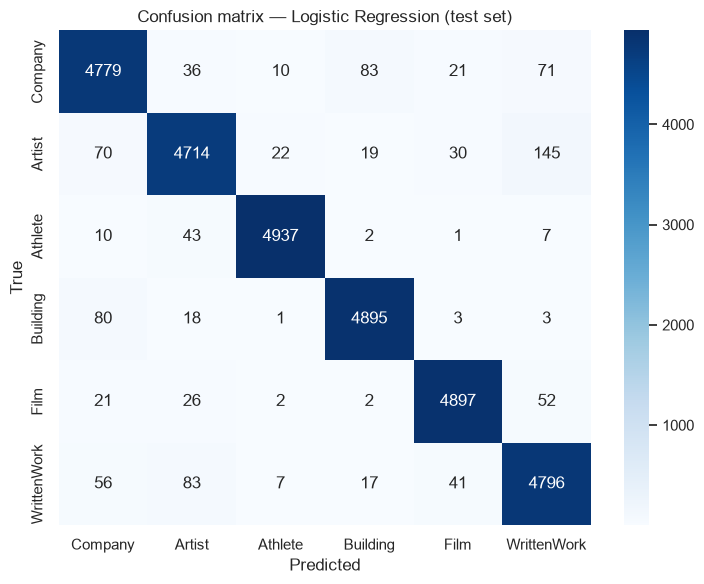

,true,predicted,count
0,Artist,WrittenWork,145
1,Company,Building,83
2,WrittenWork,Artist,83
3,Building,Company,80
4,Company,WrittenWork,71
5,Artist,Company,70
6,WrittenWork,Company,56
7,Film,WrittenWork,52


In [18]:
cm = confusion_matrix(y_test, y_pred, labels=SELECTED_CLASSES)
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=SELECTED_CLASSES, yticklabels=SELECTED_CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix — {best_name} (test set)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'confusion_matrix.png'), dpi=120); plt.show()

pairs = [(SELECTED_CLASSES[i], SELECTED_CLASSES[j], cm[i, j]) for i in range(6) for j in range(6) if i != j]
pd.DataFrame(sorted(pairs, key=lambda x: -x[2])[:8], columns=['true', 'predicted', 'count'])

In [19]:
proba = model.predict_proba(X_test)
test_df['predicted'] = y_pred
test_df['confidence'] = proba.max(axis=1)
test_df['correct'] = test_df.predicted == test_df.label_name
test_df[['orig_idx', 'title', 'label_name', 'predicted', 'confidence', 'correct']] \
    .to_csv(os.path.join(RESULTS_DIR, 'test_predictions.csv'), index=False)

print('15 individual test predictions (random sample, seed 42):')
sample = test_df.sample(15, random_state=SEED)
sample.assign(text=sample.text.str[:110])[['title', 'text', 'label_name', 'predicted', 'confidence', 'correct']].round(3)

15 individual test predictions (random sample, seed 42):


,title,text,label_name,predicted,confidence,correct
2308,Desperate Fight Records,Desperate Fight Records was an independent record label in existence between 1993 and 2000 in Umeå Sweden owne,Company,Company,0.993,True
22404,Un mauvais garçon,Un mauvais garçon (English: Counsel for Romance) is a 1936 French film featuring Danielle Darrieux. The movie,Film,Film,0.995,True
23397,Breaking Point (2005 film),Breaking Point (French: Point de rupture) is a Canadian documentary film released in 2005. Aired on CBC Televi,Film,Film,1.000,True
25058,Baby Crockett,Baby Crockett was one of the longest running comic strips that ran from The Beezer issue 34 (September 1956) t,WrittenWork,Artist,0.413,False
2664,Dhaka Bank Limited,Dhaka Bank Limited is a private-owned commercial bank in Bangladesh. Its headquarters are situated in the coun,Company,Company,1.000,True
8511,Genco Ecer,Genco Ecer (Turkish: [ˈɡendʒo ˈedʒeɾ]; born 13 December 1985 Ankara Turkey) is a Turkish Cypriot singer and at,Artist,Artist,0.973,True
5148,Andy Worthington,Andy Worthington is a British historian investigative journalist and film director.He has published three book,Artist,Artist,0.491,True
7790,Ai Jing,Ai Jing (Chinese: 艾敬; pinyin: Ài Jìng; born 10 September 1969 in Shenyang Liaoning) is a mainland Chinese sing,Artist,Artist,1.000,True
11311,Michael Seager,Michael Anthony John Seager (born 8 December 1947) is a former Zimbabwean cricketer. Seager was a left-handed,Athlete,Athlete,1.000,True
19043,St. Paul The Apostle Church (Toronto),St. Paul The Apostle is a Roman Catholic church in Toronto Canada. It is located at Dundas Street West in the,Building,Building,1.000,True


### Error analysis

In [20]:
errors = test_df[~test_df.correct]
errors[['orig_idx', 'title', 'label_name', 'predicted', 'confidence', 'text']].round(3) \
  .to_csv(os.path.join(RESULTS_DIR, 'misclassified_examples.csv'), index=False)
print(f'Misclassified: {len(errors):,} of {len(test_df):,} ({len(errors) / len(test_df):.2%})')
print(f'Mean confidence — correct: {test_df[test_df.correct].confidence.mean():.3f}, wrong: {errors.confidence.mean():.3f}\n')
for _, row in errors.sample(8, random_state=SEED).iterrows():
    print(f'[{row.label_name} -> predicted {row.predicted}, conf {row.confidence:.2f}] {row.title}')
    print('   ', row.text[:260], '\n')

Misclassified: 982 of 30,000 (3.27%)


Mean confidence — correct: 0.968, wrong: 0.716

[WrittenWork -> predicted Building, conf 0.91] Catholic World
    Catholic World was a periodical founded by Paulist Father Isaac Thomas Hecker in April 1865. It featured many articles by Orestes Brownson including the May 1870 essay Church and State which described Brownson's understanding of the proper relationship between 

[WrittenWork -> predicted Artist, conf 0.98] American Vampire
    American Vampire is an Eisner Award-winning comic book series created by writer Scott Snyder and Rafael Albuquerque.The series imagines vampires as a population made up of many different secret species and charts moments of vampire evolution and inter-species  

[WrittenWork -> predicted Company, conf 0.50] National Geographic Adventure (magazine)
    National Geographic Adventure was a magazine started in 1999 by the National Geographic Society in the United States. 

[Artist -> predicted Athlete, conf 0.50] Carlos Barbosa-Lima
    Antonio Carlos Rib

In [21]:
# Most influential words per class (what the model actually learned)
clf = model.named_steps['clf']
feats = vectorizer.get_feature_names_out()
if hasattr(clf, 'coef_'):
    weights = clf.coef_
else:  # Naive Bayes: log P(word|class) minus the average over classes
    weights = clf.feature_log_prob_ - clf.feature_log_prob_.mean(axis=0)
pd.DataFrame([{'class': c, 'rank': r + 1, 'word_or_pair': feats[j], 'weight': round(float(weights[i][j]), 3)}
              for i, c in enumerate(clf.classes_) for r, j in enumerate(np.argsort(weights[i])[::-1][:20])]) \
  .to_csv(os.path.join(RESULTS_DIR, 'top_features.csv'), index=False)
pd.DataFrame({c: [feats[j] for j in np.argsort(weights[i])[::-1][:12]] for i, c in enumerate(clf.classes_)})

,Artist,Athlete,Building,Company,Film,WrittenWork
0,born,born,museum,company,film,novel
1,painter,footballer,built,manufacturer,directed,newspaper
2,singer,player,located,founded,documentary,published
3,writer,football,church,publisher,starring,book
4,author,professional,castle,airline,movie,written
5,musician,played,building,label,film directed,play
6,actor,championship,hospital,brand,released,magazine
7,poet,cricketer,historic,chain,based,journal
8,artist,boxer,mall,based,film released,manga
9,actress,competed,house,inc,set,series


**Interpretation of the results**
- The classifier is highly accurate on 30,000 unseen articles; precision and recall are high and balanced for all
  six classes, so no class is being sacrificed for another.
- The most influential words per class match the distinctive N-grams found in Section 4 (e.g. *film, directed*
  for Film; *novel, book, published* for WrittenWork; *player, league, played* for Athlete).
- **Where errors happen** (see the confusion matrix and examples): mostly between semantically close types —
  **Artist → WrittenWork** (writers, cartoonists and memoir authors are described with *book, published, novel*),
  **Company ↔ Building** (restaurant chains, hotels, shops and factories are both businesses and places), and
  Artist → Company (designers and producers described through the companies they worked for).
  Athlete and Film are the easiest classes: their vocabulary (*footballer, league, played* / *directed, starring*)
  is used by almost no other class.
- Many errors are **words pointing to the wrong type**: the Catholic periodical *Catholic World* mentions a
  *church* and a *father* and is predicted as Building; the comic book *American Vampire* is described through the
  *writer* who created it and is predicted as Artist; the *Arden* estate (Building) is described through the
  *railroad magnate* who owned it and is predicted as Company. Bag of Words counts the words but cannot tell
  *what the article is about* from *what it mentions*.
- Some errors are **label noise**: *Wea*, a Native American tribe, is labelled Company in DBpedia — no model
  could get this "right".
- Wrong predictions have clearly lower confidence than correct ones, so the probability output is useful for
  flagging uncertain cases.
- **Limitations:** Bag of Words ignores word order and meaning ("not a film" vs "a film"); synonyms are treated
  as unrelated features; very short or list-like abstracts give little evidence. These motivate embeddings and
  Transformer models in Project 2.

## 8. Demo — classify new text

In [22]:
def predict_article_type(text, show=True):
    clean = preprocess(text, as_string=True)
    probs = model.predict_proba([clean])[0]
    ranked = sorted(zip(model.classes_, probs), key=lambda x: -x[1])
    if show:
        print(f'Text: {text[:120]}{"..." if len(text) > 120 else ""}')
        print(f'  -> {ranked[0][0]}  ({ranked[0][1]:.1%})   runner-up: {ranked[1][0]} ({ranked[1][1]:.1%})\n')
    return ranked[0][0]

new_texts = [  # written for this demo, not taken from the corpus
    'Nova Robotics is a technology firm headquartered in Austin Texas that develops warehouse automation software. It was founded in 2015.',
    'Maria Lopez is a Spanish painter and sculptor whose works have been exhibited in Madrid and Paris.',
    'Daniel Okafor is a Nigerian professional footballer who plays as a striker for a club in the English Premier League.',
    'The Harbour Tower is a 40-storey skyscraper completed in 1998 in the city centre and designed by a local architect.',
    'Silent Orbit is a 2019 science fiction thriller directed by James Reed and starring two astronauts stranded in space.',
    'The Glass Garden is a novel by a British author published in 2004 that follows three generations of one family.',
]
for t in new_texts:
    predict_article_type(t)

Text: Nova Robotics is a technology firm headquartered in Austin Texas that develops warehouse automation software. It was fou...
  -> Company  (99.2%)   runner-up: WrittenWork (0.4%)

Text: Maria Lopez is a Spanish painter and sculptor whose works have been exhibited in Madrid and Paris.
  -> Artist  (98.0%)   runner-up: Company (0.8%)

Text: Daniel Okafor is a Nigerian professional footballer who plays as a striker for a club in the English Premier League.
  -> Athlete  (99.2%)   runner-up: WrittenWork (0.6%)

Text: The Harbour Tower is a 40-storey skyscraper completed in 1998 in the city centre and designed by a local architect.
  -> Building  (97.9%)   runner-up: Artist (0.8%)

Text: Silent Orbit is a 2019 science fiction thriller directed by James Reed and starring two astronauts stranded in space.
  -> Film  (98.1%)   runner-up: WrittenWork (0.8%)

Text: The Glass Garden is a novel by a British author published in 2004 that follows three generations of one family.
  -> WrittenWor

In [23]:
# Interactive demo: uncomment and run, then type any article-like text.
# predict_article_type(input('Enter a short article text: '))

## 9. Summary

In [24]:
summary = pd.Series({
    'Corpus': 'DBpedia-14 (6 classes, content only)',
    'Train / Test documents': f'{len(train_df):,} / {len(test_df):,} (official test split)',
    'Vocabulary after preprocessing (train)': f"{stats['vocabulary size after preprocessing (train)']:,}",
    'BoW features (min_df=2)': f'{len(feats):,}',
    'LM test perplexity, interpolated bigram / trigram': f"{ppl.iloc[1, 2]} / {ppl.iloc[3, 2]}",
    'Selected classifier (validation set)': f'{best_cfg[0]}, {val_table.iloc[0]["features"]}, {val_table.iloc[0]["setting"]}',
    'Test accuracy': f'{acc:.4f}',
    'Test macro F1': f'{f1:.4f}',
}, name='value')
summary.to_frame()

,value
Corpus,"DBpedia-14 (6 classes, content only)"
Train / Test documents,"18,000 / 30,000 (official test split)"
Vocabulary after preprocessing (train),"56,723"
BoW features (min_df=2),"63,388"
"LM test perplexity, interpolated bigram / trigram",287.7 / 254.0
Selected classifier (validation set),"Logistic Regression, words + word pairs, C=1.0"
Test accuracy,0.9673
Test macro F1,0.9673


### Files kept for Project 2
| Path | Content |
|---|---|
| `data/train.csv`, `data/test.csv` | Frozen split (with `orig_idx` into the official DBpedia-14 splits) |
| `src/preprocessing.py` | Reusable preprocessing function |
| `src/ngram_lm.py` | N-gram language model |
| `models/bow_classifier.joblib` | Trained pipeline (CountVectorizer + Logistic Regression), used by `demo.py` |
| `models/bow_vectorizer.joblib`, `models/classifier.joblib`, `models/config.json` | The two parts saved separately + the chosen settings |
| `results/*.csv` | Every table in this notebook: statistics, N-grams, LM, validation experiments, metrics, errors |
| `results/figures/` | Figures used in the report and presentation |

**References:** Zhang, X., Zhao, J., LeCun, Y. (2015). *Character-level Convolutional Networks for Text
Classification*. NeurIPS — DBpedia-14 dataset (Hugging Face: `fancyzhx/dbpedia_14`).
Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft), chapters on N-grams and text classification.
Libraries: NLTK, scikit-learn, pandas, matplotlib, seaborn.